In [1]:
import os
import scanpy as sc
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

In [2]:
pth = os.path.join('..', '..', '..')
pth_in = os.path.join(pth, 'data', 'cancer', 'CCCA')
pth_out = os.path.join(pth, 'figures', 'cancer', 'CCCA')

In [3]:
adata = sc.read_h5ad(os.path.join(pth_in, 'malignant.h5ad'))
adata

AnnData object with n_obs × n_vars = 1406087 × 513
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'ebv', 'celltype', 'Title', 'Category', 'Disease', 'Technology', 'Samples', 'Cells', 'Name', 'patient', 'cell_subtype', 'source', 'disease', 'p16_status', 'site', 't_stage', 'n_stage', 'gender', 'race', 'age', 'tobacco_use', 'alcohol_use', 'hpv', 'hpv_score', 'treatment', 'procedure', 'sorting', 'cluster', 'malignant', 'sample_id', 'cell_subtype_clusters', 'tnm_stage', 'viral', 'location', 'cancer_type', 'treatment_exposure', 'treatment_response', 'cell_lineage', 'type', 'clusters_by_authors', 'cell_QCpass', 'is_tumor', 'cell_compartment', 'cluster_assignment', 'metastasis', 'sex', 'prior_enzalutamide', 'prior_abiraterone', 'prior_taxane', 'prior_platinum', 'prior_sipuleucel_T', 'purity', 'has_bulk_RNA', 'cancer_cell_state', 'PSA', 'source_region', 'gleason_score', 'ERG_status', 'cores

/tmp/ipykernel_1408239/3313446217.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  n_src = grp.apply(lambda sdf: sdf.source.nunique())
/tmp/ipykernel_1408239/3313446217.py:5: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  n_samples = grp.apply(lambda sdf: sdf['sample'].nunique())


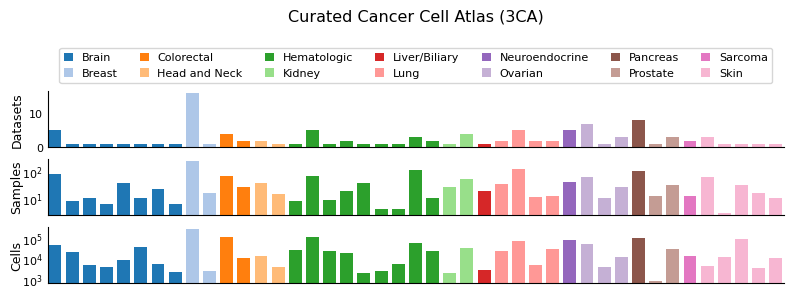

In [11]:
# plot summary statistics
by = ['Category', 'Disease']
grp = adata.obs.groupby(by, observed = True)
n_src = grp.apply(lambda sdf: sdf.source.nunique())
n_samples = grp.apply(lambda sdf: sdf['sample'].nunique())
n_cells = grp.size()
cmap, cat = plt.cm.tab20, n_src.index.get_level_values(0)
cmap = {ix : cmap(i) for i, ix in enumerate(cat.unique())}
c = [cmap[ix] for ix in cat]

w, fs1, fs2, fs3, ms = .75, 9, 8, 11.5, .8
fig, ax = plt.subplots(3, 1, figsize = (9.5, 2.5))
n_src.plot(kind = 'bar', width = w, color = c, ax = ax[0])
n_samples.plot(kind = 'bar', width = w, color = c, ax = ax[1])
n_cells.plot(kind = 'bar', width = w, color = c, ax = ax[2])
ax[0].set_ylabel('Datasets', size = fs1)
ax[1].set_ylabel('Samples', size = fs1, va = 'center')
ax[2].set_ylabel('Cells', size = fs1, va = 'center')

xlim = ax[0].get_xlim()
for i in range(3):
    ax[i].set_xticks([]); ax[i].set_xlabel('')
    ax[i].tick_params('y', which = 'both', size = 0, labelsize = fs2)
    for sp in ('top', 'right'): ax[i].spines[sp].set_visible(False)
    if i > 0: ax[i].set_yscale('log')
    ax[i].set_xlim(xlim[0] + .2, xlim[1] - .15)

ax[0].set_title('Curated Cancer Cell Atlas (3CA)', pad = 50, size = fs3)
handles = [Patch(facecolor = val, label = key) for key, val in cmap.items()]
ax[0].legend(handles = handles, ncols = len(handles) // 2,
             fontsize = fs2, handlelength = ms, handleheight = ms,
             loc = 'upper center', bbox_to_anchor = (.5, 1.85))

fn = os.path.join(pth_out, 'overview.pdf')
plt.savefig(fn, bbox_inches = 'tight')